# Previsão de Cancelamento de Clientes (Churn) com Machine Learning

**Autor:** Kauê Salazar Cardoso — Análise e Desenvolvimento de Sistemas (IFRS Campus Rolante)

Este notebook mostra um pipeline completo de Machine Learning feito com **pandas** e **scikit-learn**: escolhemos os dados, fazemos a limpeza, treinamos dois modelos e comparamos qual deles se sai melhor.


## 1. O problema de negócio

### O que é churn?
*Churn* é quando um cliente cancela o serviço e vai embora. Para uma empresa de telefonia e internet, isso pesa muito: conquistar um cliente novo costuma sair bem mais caro do que manter um que já existe.

### Para que serve essa previsão?
A ideia é descobrir, **antes** que aconteça, quais clientes têm mais chance de cancelar. Com essa lista em mãos, a empresa pode agir a tempo, por exemplo oferecendo um desconto, um plano melhor ou um atendimento mais atencioso.

### Quem se beneficia?
- **Equipe de retenção / atendimento:** sabe em quem focar primeiro, sem precisar ligar para todo mundo.
- **Marketing:** consegue criar campanhas para o público certo.
- **Gestão da empresa:** perde menos receita e entende os motivos que levam ao cancelamento.
- **O próprio cliente:** recebe ofertas e ajuda antes de ficar insatisfeito de vez.

### O dataset
Usamos o **Telco Customer Churn**, um dataset público da IBM (também disponível no [Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)). Ele tem cerca de 7 mil clientes, com informações como tipo de contrato, serviços contratados, valor da mensalidade e, o mais importante, se o cliente cancelou ou não (coluna `Churn`).

Como a resposta é **sim ou não**, este é um problema de **Classificação**.

## 2. Importando as bibliotecas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

# Deixa os resultados iguais toda vez que o notebook rodar
SEMENTE = 42
sns.set_theme(style="whitegrid")

## 3. Carregando os dados com pandas

In [ ]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL)

print(f"O dataset tem {df.shape[0]} linhas (clientes) e {df.shape[1]} colunas.")
df.head()

O dataset tem 7043 linhas (clientes) e 21 colunas.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Análise exploratória

Antes de treinar qualquer coisa, vale a pena olhar os dados com calma: quais colunas existem, de que tipo elas são e se tem algo estranho.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Valores ausentes e dados duplicados

In [ ]:
print(f"Total de valores ausentes (NaN): {df.isnull().sum().sum()}")

print(f"\nLinhas totalmente duplicadas: {df.duplicated().sum()}")
print(f"Linhas duplicadas sem contar o customerID: {df.drop(columns=['customerID']).duplicated().sum()}")

Total de valores ausentes (NaN): 0

Linhas totalmente duplicadas: 0
Linhas duplicadas sem contar o customerID: 22


À primeira vista não tem nenhum `NaN`. Mas, sem contar o código do cliente, existem **22 linhas repetidas**, ou seja, clientes com exatamente as mesmas informações. Elas serão removidas no tratamento.

Repare que a coluna `TotalCharges` (valor total já pago) aparece como **texto** (`object`), mas deveria ser número. Isso acontece porque alguns clientes têm um espaço em branco no lugar do valor. Vamos ver quantos são:

In [ ]:
espacos = (df["TotalCharges"].str.strip() == "").sum()
print(f"Clientes com TotalCharges em branco: {espacos}")
df[df["TotalCharges"].str.strip() == ""][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Clientes com TotalCharges em branco: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Todos eles têm `tenure = 0`, ou seja, acabaram de entrar e ainda não pagaram nada. Esses espaços em branco são, na prática, **valores ausentes escondidos**, e vamos tratar isso na limpeza.

### Quantos clientes cancelaram?

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Taxa de cancelamento: 26.5%


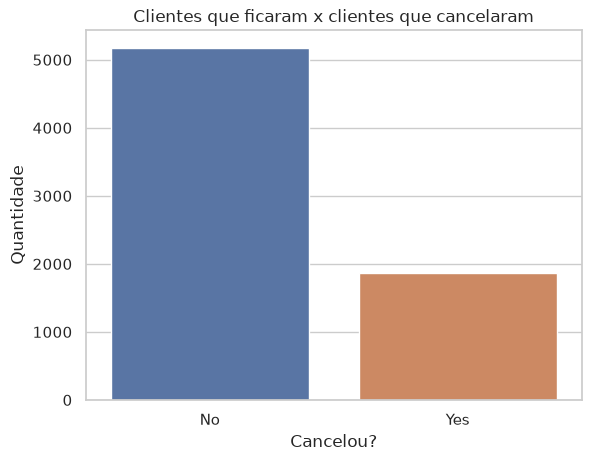

In [ ]:
contagem = df["Churn"].value_counts()
print(contagem)
print(f"\nTaxa de cancelamento: {contagem['Yes'] / len(df):.1%}")

sns.countplot(data=df, x="Churn", hue="Churn", palette=["#4C72B0", "#DD8452"], legend=False)
plt.title("Clientes que ficaram x clientes que cancelaram")
plt.xlabel("Cancelou?")
plt.ylabel("Quantidade")
plt.show()

Cerca de **1 em cada 4 clientes** cancelou. As classes não estão equilibradas (tem muito mais "Não" do que "Sim"). Por isso, além da acurácia, vamos olhar outras métricas como **recall** e **F1**, que mostram se o modelo realmente encontra quem vai cancelar.

### Tipo de contrato x cancelamento

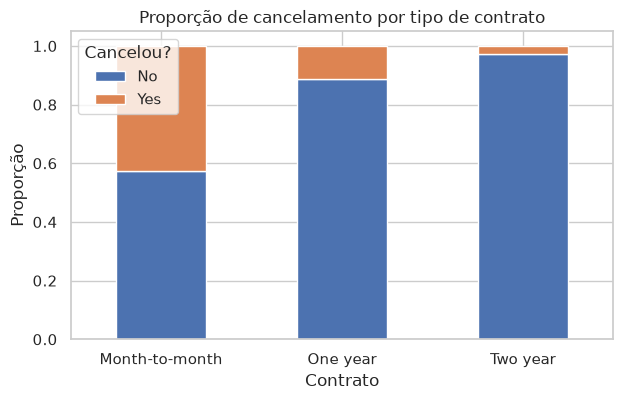

In [ ]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index").plot(
    kind="bar", stacked=True, color=["#4C72B0", "#DD8452"], figsize=(7, 4))
plt.title("Proporção de cancelamento por tipo de contrato")
plt.ylabel("Proporção")
plt.xlabel("Contrato")
plt.xticks(rotation=0)
plt.legend(title="Cancelou?")
plt.show()

Dá para ver que quem tem contrato **mês a mês** cancela muito mais do que quem tem contrato de 1 ou 2 anos. Faz sentido: é mais fácil sair quando não tem fidelidade.

### Tempo de casa e mensalidade

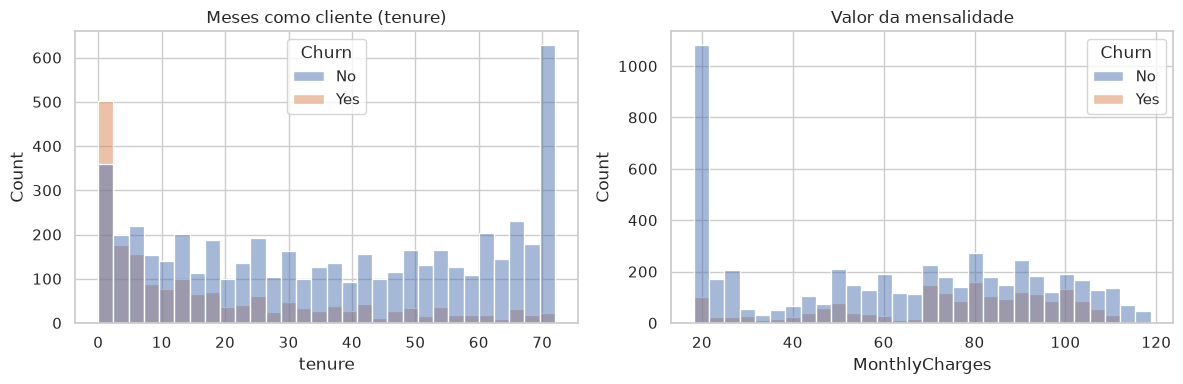

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=eixos[0], palette=["#4C72B0", "#DD8452"])
eixos[0].set_title("Meses como cliente (tenure)")
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, ax=eixos[1], palette=["#4C72B0", "#DD8452"])
eixos[1].set_title("Valor da mensalidade")
plt.tight_layout()
plt.show()

Clientes **novos** e com **mensalidade mais alta** aparecem mais entre os que cancelam. Essas pistas ajudam a entender o que o modelo vai aprender.

## 5. Tratamento dos dados

Aqui fazemos a limpeza:
1. Tiramos a coluna `customerID`, que é só um código e não ajuda a prever nada.
2. Convertemos `TotalCharges` para número.
3. **Eliminamos os valores ausentes.**
4. **Removemos as linhas duplicadas.**
5. Transformamos a coluna `Churn` em 0 (não cancelou) e 1 (cancelou).

In [ ]:
dados = df.drop(columns=["customerID"]).copy()

# Converte para número; o que não for número (os espaços em branco) vira NaN
dados["TotalCharges"] = pd.to_numeric(dados["TotalCharges"], errors="coerce")

print("Valores ausentes por coluna (só as que têm algum):")
print(dados.isnull().sum()[dados.isnull().sum() > 0])

antes = len(dados)
dados = dados.dropna()
print(f"\nLinhas removidas por valores ausentes: {antes - len(dados)}")

antes = len(dados)
dados = dados.drop_duplicates()
print(f"Linhas duplicadas removidas: {antes - len(dados)}")

dados["Churn"] = dados["Churn"].map({"No": 0, "Yes": 1})

print(f"\nTamanho final do dataset: {dados.shape}")

Valores ausentes por coluna (só as que têm algum):
TotalCharges    11
dtype: int64

Linhas removidas por valores ausentes: 11
Linhas duplicadas removidas: 22

Tamanho final do dataset: (7010, 20)


### Separando as colunas

- **X**: as informações do cliente (o que o modelo usa para prever).
- **y**: a resposta que queremos prever (`Churn`).

Também separamos as colunas **numéricas** das **categóricas** (texto), porque cada tipo recebe um tratamento diferente.

In [ ]:
X = dados.drop(columns=["Churn"])
y = dados["Churn"]

colunas_numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
colunas_categoricas = [col for col in X.columns if col not in colunas_numericas]

print("Numéricas:", colunas_numericas)
print("Categóricas:", colunas_categoricas)

Numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### Padronização e codificação

- **Colunas numéricas → padronização (`StandardScaler`)**: deixa todas na mesma escala (média 0 e desvio padrão 1). Sem isso, `TotalCharges` (que chega a milhares) "gritaria" mais alto que `tenure` (que vai até 72) só por ter números maiores.
- **Colunas categóricas → `OneHotEncoder`**: os modelos só entendem números, então cada categoria vira uma coluna de 0 ou 1. Exemplo: `Contract` vira `Contract_Month-to-month`, `Contract_One year` e `Contract_Two year`.

Colocamos tudo dentro de um `ColumnTransformer` e depois de um `Pipeline`. Assim, o tratamento é **aprendido só com os dados de treino** e aplicado igualzinho no teste, sem "vazar" informação do teste para o modelo.

In [ ]:
preprocessamento = ColumnTransformer([
    ("numericas", StandardScaler(), colunas_numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), colunas_categoricas),
])

## 6. Divisão em treino e teste (80/20)

- **80%** dos dados vão para o **treino**: é com eles que o modelo aprende.
- **20%** ficam guardados para o **teste**: servem para ver se o modelo funciona com clientes que ele nunca viu.

O `stratify=y` garante que a proporção de cancelamentos seja a mesma nos dois grupos.

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEMENTE, stratify=y)

print(f"Treino: {X_treino.shape[0]} clientes")
print(f"Teste:  {X_teste.shape[0]} clientes")
print(f"Taxa de churn no treino: {y_treino.mean():.1%} | no teste: {y_teste.mean():.1%}")

Treino: 5608 clientes
Teste:  1402 clientes
Taxa de churn no treino: 26.5% | no teste: 26.5%


## 7. Escolha dos algoritmos e treinamento

Vamos testar dois algoritmos bem diferentes entre si:

| Algoritmo | Como funciona (bem resumido) | Ponto forte |
|---|---|---|
| **Regressão Logística** | Calcula uma "nota" para cada cliente somando o peso de cada característica e transforma isso numa probabilidade de cancelar. | Simples, rápida e fácil de explicar. |
| **Random Forest** | Cria várias árvores de decisão, cada uma vendo uma parte dos dados, e no fim elas "votam" no resultado. | Pega relações mais complexas entre as variáveis. |

Nos dois usamos `class_weight="balanced"`, que faz o modelo dar mais atenção aos clientes que cancelam (a classe menor). Sem isso, o modelo tende a chutar "não cancela" para quase todo mundo.

In [ ]:
modelos = {
    "Regressão Logística": Pipeline([
        ("preprocessamento", preprocessamento),
        ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEMENTE)),
    ]),
    "Random Forest": Pipeline([
        ("preprocessamento", preprocessamento),
        ("modelo", RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5,
                                          class_weight="balanced", random_state=SEMENTE, n_jobs=-1)),
    ]),
}

for nome, pipeline in modelos.items():
    pipeline.fit(X_treino, y_treino)
    print(f"✔ {nome} treinado")

✔ Regressão Logística treinado


/tmp/claude-0/-home-claude/3b6d1c5d-2285-59cc-8340-c8dd1455f93f/scratchpad/venv12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


✔ Random Forest treinado


## 8. Avaliação dos modelos

Agora usamos os 20% de teste. As métricas significam:

- **Acurácia:** de todos os clientes, quantos o modelo acertou.
- **Precisão:** dos que o modelo disse que iam cancelar, quantos realmente cancelaram.
- **Recall:** dos que realmente cancelaram, quantos o modelo conseguiu encontrar. **É a mais importante para o negócio**, porque cliente que cancela sem ser percebido é receita perdida.
- **F1:** um equilíbrio entre precisão e recall.
- **ROC AUC:** mostra o quanto o modelo sabe separar quem cancela de quem fica (1 é perfeito, 0,5 é chute).

In [ ]:
resultados = []
for nome, pipeline in modelos.items():
    previsao = pipeline.predict(X_teste)
    probabilidade = pipeline.predict_proba(X_teste)[:, 1]
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, previsao),
        "Precisão": precision_score(y_teste, previsao),
        "Recall": recall_score(y_teste, previsao),
        "F1": f1_score(y_teste, previsao),
        "ROC AUC": roc_auc_score(y_teste, probabilidade),
    })

tabela = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabela

,Acurácia,Precisão,Recall,F1,ROC AUC
Modelo,,,,,
Regressão Logística,0.744,0.511,0.776,0.616,0.846
Random Forest,0.766,0.544,0.722,0.620,0.843


In [ ]:
for nome, pipeline in modelos.items():
    print(f"===== {nome} =====")
    print(classification_report(y_teste, pipeline.predict(X_teste),
                                target_names=["Ficou", "Cancelou"]))

===== Regressão Logística =====
              precision    recall  f1-score   support

       Ficou       0.90      0.73      0.81      1031
    Cancelou       0.51      0.78      0.62       371

    accuracy                           0.74      1402
   macro avg       0.71      0.75      0.71      1402
weighted avg       0.80      0.74      0.76      1402

===== Random Forest =====


              precision    recall  f1-score   support

       Ficou       0.89      0.78      0.83      1031
    Cancelou       0.54      0.72      0.62       371

    accuracy                           0.77      1402
   macro avg       0.72      0.75      0.73      1402
weighted avg       0.80      0.77      0.78      1402



### Matriz de confusão

Mostra onde cada modelo acerta e onde erra:
- **Canto inferior direito:** clientes que cancelaram e o modelo pegou ✅
- **Canto inferior esquerdo:** clientes que cancelaram e o modelo deixou passar ❌

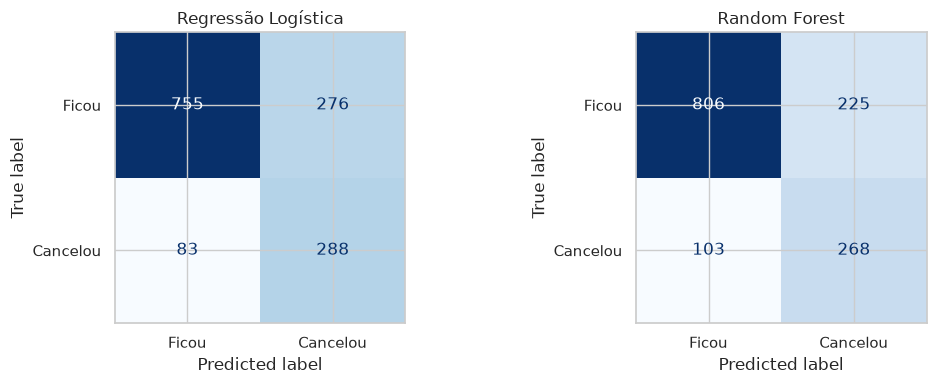

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for eixo, (nome, pipeline) in zip(eixos, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipeline, X_teste, y_teste, display_labels=["Ficou", "Cancelou"],
        cmap="Blues", ax=eixo, colorbar=False)
    eixo.set_title(nome)
plt.tight_layout()
plt.show()

### Comparando lado a lado

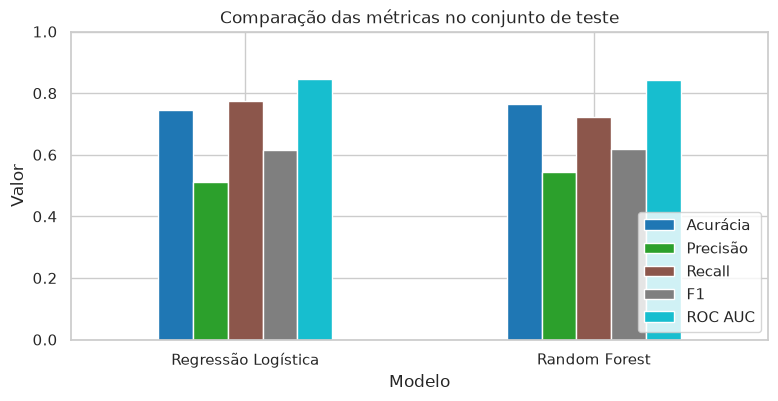

In [ ]:
tabela.plot(kind="bar", figsize=(9, 4), rot=0, colormap="tab10")
plt.title("Comparação das métricas no conjunto de teste")
plt.ylim(0, 1)
plt.ylabel("Valor")
plt.legend(loc="lower right")
plt.show()

## 9. O que mais pesa no cancelamento?

O Random Forest consegue dizer quais características ele mais usou para decidir. Isso ajuda a empresa a entender **por que** os clientes saem.

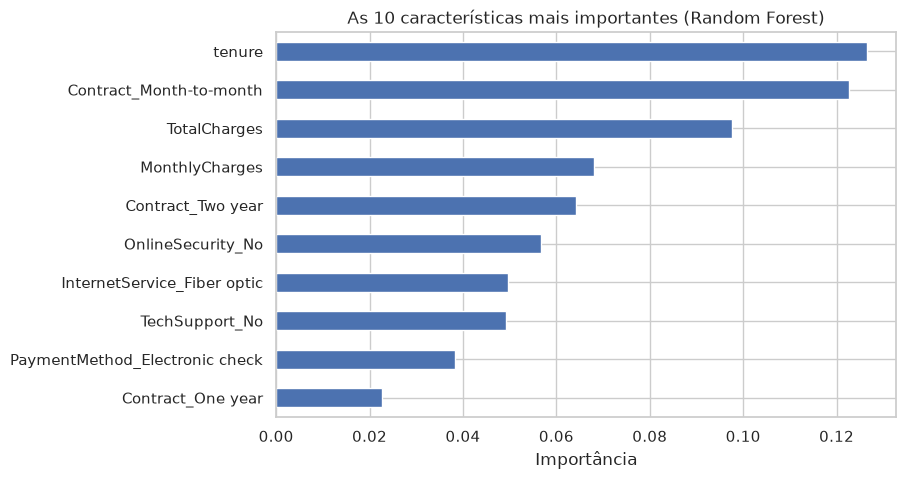

In [ ]:
rf = modelos["Random Forest"]
nomes = rf.named_steps["preprocessamento"].get_feature_names_out()
nomes = [n.split("__", 1)[1] for n in nomes]  # tira o prefixo "numericas__" / "categoricas__"

importancias = (pd.Series(rf.named_steps["modelo"].feature_importances_, index=nomes)
                .sort_values(ascending=False).head(10))

importancias.sort_values().plot(kind="barh", figsize=(8, 5), color="#4C72B0")
plt.title("As 10 características mais importantes (Random Forest)")
plt.xlabel("Importância")
plt.show()

## 10. Conclusão

In [ ]:
melhor = tabela["F1"].idxmax()
print(f"Melhor modelo pelo F1: {melhor}")
print(tabela.loc[melhor])

Melhor modelo pelo F1: Random Forest
Acurácia    0.766
Precisão    0.544
Recall      0.722
F1          0.620
ROC AUC     0.843
Name: Random Forest, dtype: float64


### Qual algoritmo apresentou melhor resultado?
O **Random Forest** foi um pouco melhor: teve mais acurácia (76,6% contra 74,4%), mais precisão (54,4% contra 51,1%) e o maior F1 (0,620 contra 0,616). Já a Regressão Logística encontrou mais clientes que iam cancelar (recall de 77,6% contra 72,2%). Ou seja, os dois funcionam bem e a diferença é pequena, mas no geral o Random Forest leva uma leve vantagem.

### O modelo conseguiu fazer boas previsões?
Sim. O ROC AUC ficou perto de **0,84** nos dois modelos, bem acima de 0,5 (que seria um chute). E o mais importante: eles encontram **cerca de 3 em cada 4 clientes que realmente vão cancelar** (recall entre 72% e 78%).

O ponto fraco é a precisão, que fica entre 51% e 54%: alguns clientes que não iam sair também entram na lista de "risco". Para esse tipo de problema, isso é aceitável, porque oferecer um desconto para quem ia ficar custa bem menos do que perder um cliente de vez.

### Como isso poderia ajudar uma empresa?
- A equipe de retenção recebe uma **lista dos clientes com maior risco** e liga primeiro para eles, sem perder tempo com quem está satisfeito.
- O marketing pode criar **ofertas certeiras**, por exemplo incentivar quem tem contrato mês a mês a mudar para um plano anual.
- Os fatores que mais pesam no cancelamento são o **contrato mês a mês**, o **pouco tempo de casa** e os **valores cobrados**. Então a empresa sabe onde agir: cuidar bem dos clientes nos primeiros meses e revisar os preços dos planos mais caros.
- No fim, menos clientes cancelando significa **mais receita** e menos gasto para conquistar clientes novos.

### Próximos passos
- Testar outros algoritmos (por exemplo Gradient Boosting).
- Ajustar os parâmetros com `GridSearchCV`.
- Usar validação cruzada para ter uma avaliação ainda mais confiável.